# Tongji EV rest periods

This notebook lists the released vehicles and cells, loads the rest segments of one field vehicle, and plots pack voltage. It makes no diagnosis.

## 1. Released units

This step lists what `systems('tongji_rest')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('tongji_rest')
display(released)

,unit,kind,chemistry,charge_segments,rest_segments,first,last,feature_files
0,LFP01,field vehicle,LFP,805,797,2021-07-12 00:57:33,2024-05-30 09:21:47,1
1,NMC01_Car01,field vehicle,NMC,553,533,2021-09-18 00:52:19,2023-04-01 00:33:16,1
2,NMC01_Car02,field vehicle,NMC,712,712,2021-09-18 00:52:19,2023-12-20 15:03:18,1
3,NMC02,field vehicle,NMC,504,440,2020-09-29 14:30:17,2023-12-27 23:27:15,1
4,LFP01_01,feature only,LFP,0,0,NaT,NaT,2
...,...,...,...,...,...,...,...,...
110,NMC03_14,feature only,NMC,0,0,NaT,NaT,1
111,NMC03_15,feature only,NMC,0,0,NaT,NaT,1
112,NMC03_17,feature only,NMC,0,0,NaT,NaT,1
113,NMC03_18,feature only,NMC,0,0,NaT,NaT,2


The four field vehicles have raw segments. The other rows appear only in derived feature workbooks, as vehicles or laboratory cells.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('tongji_rest', unit='NMC02', kind='rest')
print(frame.shape)
display(frame.head())

(9819, 102)


,segment,index,reqDate,totalVoltage,totalCurrent,soc,cellVoltage_1,cellVoltage_2,cellVoltage_3,cellVoltage_4,...,cellVoltage_87,cellVoltage_88,cellVoltage_89,cellVoltage_90,cellVoltage_91,cellVoltage_92,cellVoltage_93,cellVoltage_94,accumulatedMileage,temp_mean
0,rest_seg_1,1683,2020-09-29 14:57:49,390.177,-62.066168,93.0,4.107,4.108,4.109,4.108,...,4.108,4.107,4.107,4.106,4.108,4.104,4.111,4.108,26162.875572,39.500000
1,rest_seg_1,1684,2020-09-29 14:57:59,390.235,-64.894540,93.0,4.106,4.110,4.110,4.110,...,4.110,4.110,4.110,4.110,4.109,4.105,4.111,4.108,26162.875572,39.357143
2,rest_seg_1,1685,2020-09-29 14:58:09,390.345,-62.043789,93.0,4.109,4.109,4.111,4.109,...,4.111,4.112,4.109,4.109,4.110,4.108,4.113,4.109,26162.875572,39.357143
3,rest_seg_1,1686,2020-09-29 14:58:19,390.427,-66.025852,93.0,4.110,4.111,4.112,4.111,...,4.112,4.112,4.110,4.109,4.111,4.107,4.112,4.110,26162.875572,39.285714
4,rest_seg_1,1687,2020-09-29 14:58:29,390.502,-63.159118,93.0,4.110,4.110,4.112,4.111,...,4.111,4.112,4.112,4.112,4.111,4.107,4.115,4.112,26162.875572,39.285714


The 440 rest segments of NMC02, read from the Parquet copies made once in a throwaway environment, because the release's pickles are never unpickled here.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['totalVoltage', 'totalCurrent', 'soc', 'temp_mean']].describe().T)

,count,mean,std,min,25%,50%,75%,max
totalVoltage,9819.0,384.908815,9.676349,333.768000,383.136500,388.232000,390.829000,394.855000
totalCurrent,9819.0,-30.243041,53.022398,-270.647368,-60.368540,-14.826258,1.998254,204.799135
soc,9819.0,89.643243,13.709457,18.000000,89.000000,95.000000,98.000000,100.000000
temp_mean,9819.0,36.565638,6.161605,13.214286,34.357143,37.142857,39.785714,55.214286


These ranges are raw values as released, before any cleaning. The schema file next to the loader lists units and any sentinel codes.

## 4. A first look

This step plots one signal to show the shape of the data.

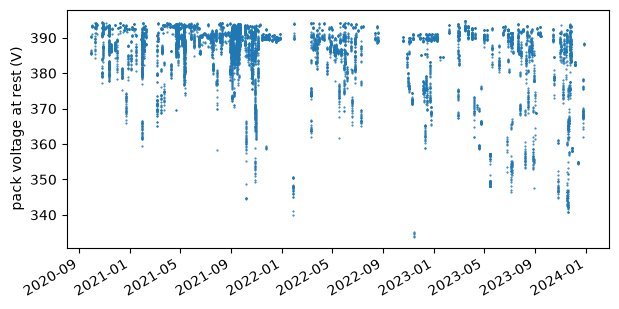

In [4]:
ax = frame.plot(x='reqDate', y='totalVoltage', style='.', ms=1, figsize=(7, 3.5), legend=False)
ax.set_xlabel('')
ax.set_ylabel('pack voltage at rest (V)')
plt.show()

Across the rest segments from September 2020 to December 2023 the pack voltage at rest ranges from 334 to 395 V. Values are raw, as released.